In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import os, time, ast
import math
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Stile base
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)

# Aggiornamenti avanzati
plt.rcParams.update({
    # Colori e sfondi
    'figure.facecolor': '#111111',
    'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111',
    'axes.edgecolor': 'white',
    'axes.labelcolor': 'white',
    'axes.titlecolor': 'white',
    'text.color': 'white',
    'xtick.color': 'lightgray',
    'ytick.color': 'lightgray',

    # Font e peso
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',

    # Griglia elegante
    'axes.grid': True,
    'grid.color': 'gray',
    'grid.linestyle': '--',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.3,  # meno invasiva

    # Tick leggeri
    'xtick.direction': 'out',
    'ytick.direction': 'out',

    # Leggibilità generale
    'legend.edgecolor': 'gray',
    'legend.facecolor': '#222222',
    'legend.fontsize': 'medium',
})

print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I MODELLI ---
# print("--- Creazione directory per i modelli ---")
# models_dir = 'models_time_series_classification/'
# os.makedirs(models_dir, exist_ok=True)
# print(f"✅ Directory per i modelli '{models_dir}' pronta.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
plots_dir = 'plots_outlier_detection/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")

# --- CARICAMENTO DEL DATASET PREPARATO ---
dataset_dir = "Dataset/"
dataset_name = "spotify_prepared.csv"
try:
    df = pd.read_csv(os.path.join(dataset_dir, dataset_name))
    print(f"✅ Dataset preparato caricato: {df.shape[0]} righe, {df.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Assicurati di aver eseguito il Modulo 0 e salvato '{dataset_name}'.")
    exit(1)



✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_outlier_detection/' pronta.
✅ Dataset preparato caricato: 113999 righe, 19 colonne.


In [2]:
df.head(10)

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres,keymode,duration_mins,genres_10
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic,C# minor,3.844433,Country/Folk & Songwriter
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic,C# major,2.493500,Country/Folk & Songwriter
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic,C major,3.513767,Country/Folk & Songwriter
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic,C major,3.365550,Country/Folk & Songwriter
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic,D major,3.314217,Country/Folk & Songwriter
5,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,0,0.688,0.4810,-8.807,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic,F# major,3.570667,Country/Folk & Songwriter
6,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,0,0.407,0.1470,-8.822,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic,D major,3.823333,Country/Folk & Songwriter
7,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,0,0.703,0.4440,-9.331,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic,B major,4.049100,Country/Folk & Songwriter
8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,0,0.625,0.4140,-8.700,0.0369,0.2940,0.000000,0.1510,0.6690,130.088,4,acoustic,C major,3.160217,Country/Folk & Songwriter
9,Ross Copperman,Hunger,Hunger,56,0,0.442,0.6320,-6.770,0.0295,0.4260,0.004190,0.0735,0.1960,78.899,4,acoustic,C# major,3.426567,Country/Folk & Songwriter


In [3]:
X = df.drop(columns=['genres', 'artists', 'album_name', 'track_name']).copy()

In [4]:
X.info(memory_usage='deep', verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113999 entries, 0 to 113998
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   popularity        113999 non-null  int64  
 1   explicit          113999 non-null  int64  
 2   danceability      113999 non-null  float64
 3   energy            113999 non-null  float64
 4   loudness          113999 non-null  float64
 5   speechiness       113999 non-null  float64
 6   acousticness      113999 non-null  float64
 7   instrumentalness  113999 non-null  float64
 8   liveness          113999 non-null  float64
 9   valence           113999 non-null  float64
 10  tempo             113999 non-null  float64
 11  time_signature    113999 non-null  int64  
 12  keymode           113999 non-null  object 
 13  duration_mins     113999 non-null  float64
 14  genres_10         113999 non-null  object 
dtypes: float64(10), int64(3), object(2)
memory usage: 26.5 MB


In [5]:
# Let's pick categorical and numerical columns separately
categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
numeric_columns = [col for col in X.columns if col not in categorical_columns]

#### Variable Transformation: OHE for categorical variables and Standardization for numeric ones

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop=None, handle_unknown='ignore')
X_ohe = ohe.fit_transform(X[categorical_columns])
X_ohe_df = pd.DataFrame(X_ohe, columns=ohe.get_feature_names_out(categorical_columns), index=X.index)

std_scaler = StandardScaler()
X_std = std_scaler.fit_transform(X[numeric_columns])
X_std_df = pd.DataFrame(X_std, columns=[f"std_{col}" for col in numeric_columns], index=X.index)

X_final = pd.concat([X_std_df, X_ohe_df], axis="columns")

In [7]:
X_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113999 entries, 0 to 113998
Data columns (total 47 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   std_popularity                       113999 non-null  float64
 1   std_explicit                         113999 non-null  float64
 2   std_danceability                     113999 non-null  float64
 3   std_energy                           113999 non-null  float64
 4   std_loudness                         113999 non-null  float64
 5   std_speechiness                      113999 non-null  float64
 6   std_acousticness                     113999 non-null  float64
 7   std_instrumentalness                 113999 non-null  float64
 8   std_liveness                         113999 non-null  float64
 9   std_valence                          113999 non-null  float64
 10  std_tempo                            113999 non-null  float64
 11  std_time_sign

In [8]:
df_final = pd.concat([df, X_final], axis="columns")

In [9]:
df_final.head()

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,...,genres_10_Classical/Ambient & Stage,genres_10_Country/Folk & Songwriter,genres_10_Electronic & Dance,genres_10_Hip-Hop & R&B,genres_10_Jazz/Soul/Funk/Blues,genres_10_Latin & Brazilian,genres_10_Metal & Hardcore,genres_10_Pop & Indie,genres_10_Rock & Alternative,genres_10_World & Regional
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Outliers Detection with LOF

#### Selecting the best n_neighbors number for LOF

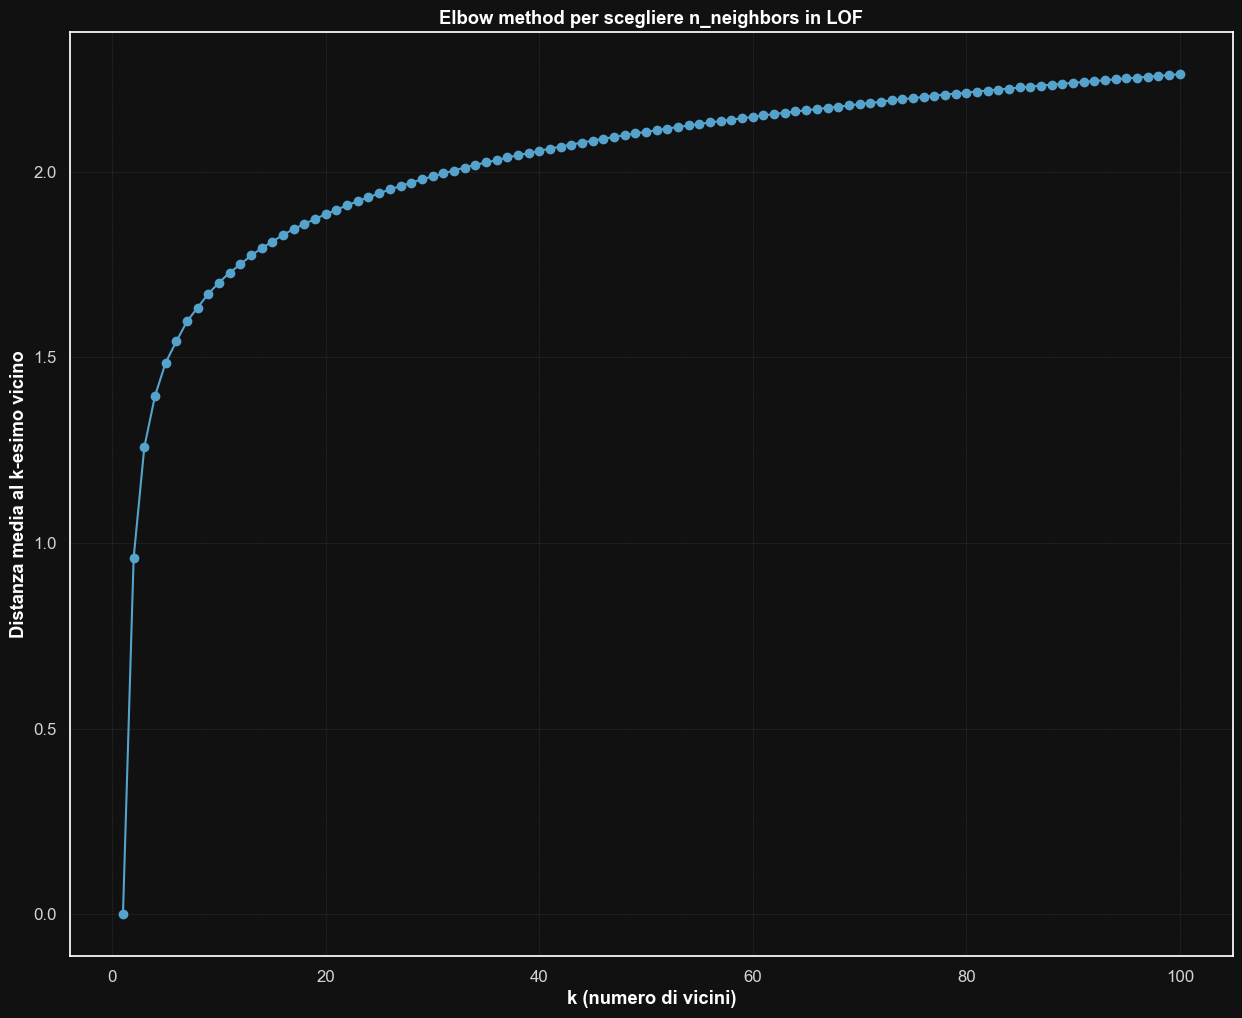

In [10]:
# Miglior approccio alla stime di un optimal_n_neighbors
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

max_k = 100
nn = NearestNeighbors(n_neighbors=max_k, n_jobs=-1).fit(X_final)
distances, _ = nn.kneighbors(X_final)

# Più efficiente che il loop in quanto faccio solo un fit, la distanza massima
# dalla matrice delle distanze restituita da nn.neighbors, mi trovo le medie delle altre distanze.
# Con questo per trovare il knee automaticamente:
avg_distances = np.mean(distances, axis=0)

plt.figure(figsize=(15,12))
plt.plot(range(1, max_k+1), avg_distances, marker='o')
plt.xlabel("k (numero di vicini)")
plt.ylabel("Distanza media al k-esimo vicino")
plt.title("Elbow method per scegliere n_neighbors in LOF")
plt.grid(True)
plt.show()

### Outilier Detection with LOF

In [11]:
from sklearn.neighbors import LocalOutlierFactor
import numpy as np

# Configurazione LOF
optimal_n_neighbors = 15
lof = LocalOutlierFactor(
   n_neighbors=optimal_n_neighbors,
   contamination=0.05, # rilevare il 5% è lo standard
   novelty=False,
   n_jobs=-1)

# Fit e predict
lof_labels = lof.fit_predict(X_final)
lof_scores = lof.negative_outlier_factor_

X_final["lof_labels"] = lof_labels
X_final["lof_scores"] = lof_scores

# Aggiungi risultati al DataFrame
df_final["lof_labels"] = lof_labels
df_final["lof_scores"] = lof_scores

# === ANALISI COMPLETA ===
print(f"🔍 LOF ANALYSIS REPORT")
print(f"{'='*50}")
print(f"Dataset shape: {df_final.shape}")
print(f"Neighbors used: {optimal_n_neighbors}")
print(f"Contamination: auto")

# Distribuzione outliers
n_outliers = np.sum(lof_labels == -1)
n_inliers = np.sum(lof_labels == 1)
outlier_rate = (n_outliers / len(df_final)) * 100

print(f"\n📊 OUTLIER DISTRIBUTION:")
print(f"Outliers (-1): {n_outliers:,} ({outlier_rate:.2f}%)")
print(f"Inliers (1): {n_inliers:,} ({100-outlier_rate:.2f}%)")

# Statistiche LOF scores
print(f"\n📈 LOF SCORES STATISTICS:")
print(f"Min score: {lof_scores.min():.4f}")
print(f"Max score: {lof_scores.max():.4f}")
print(f"Mean score: {lof_scores.mean():.4f}")
print(f"Std score: {lof_scores.std():.4f}")
print(f"Median score: {np.median(lof_scores):.4f}")

# Top 10 outliers più estremi - DETTAGLIATI
outlier_indices = np.where(lof_labels == -1)[0]
if len(outlier_indices) > 0:
   top_outliers_idx = outlier_indices[np.argsort(lof_scores[outlier_indices])[:10]]
   print(f"\n🚨 TOP 10 MOST EXTREME OUTLIERS - FULL DETAILS:")
   print(f"{'='*80}")

   for i, idx in enumerate(top_outliers_idx, 1):
       row = df_final.iloc[idx]
       print(f"\n{i:2d}. INDEX {idx} | LOF SCORE: {lof_scores[idx]:.4f}")
       print(f"    Artist(s): {row['artists']}")
       print(f"    Album: {row['album_name']}")
       print(f"    Track: {row['track_name']}")
       print(f"    Popularity: {row['popularity']}")
       print(f"    Genres: {row['genres']}")
       print(f"    Top 10 Genres: {row['genres_10']}")
       print(f"    Duration: {row['duration_mins']:.2f} mins")
       print(f"    {'-'*70}")

# Threshold automatico
threshold = np.percentile(lof_scores, 5)  # 5° percentile
print(f"\n🎯 AUTOMATIC THRESHOLD:")
print(f"5th percentile threshold: {threshold:.4f}")
print(f"Points below threshold: {np.sum(lof_scores < threshold)}")

print(f"\n✅ LOF Analysis completed!")
print(f"Columns added: 'lof_labels', 'lof_scores'")


🔍 LOF ANALYSIS REPORT
Dataset shape: (113999, 68)
Neighbors used: 15
Contamination: auto

📊 OUTLIER DISTRIBUTION:
Outliers (-1): 5,700 (5.00%)
Inliers (1): 108,299 (95.00%)

📈 LOF SCORES STATISTICS:
Min score: -23340090434.3220
Max score: -0.7739
Mean score: -27295057.8537
Std score: 519168372.8480
Median score: -1.0421

🚨 TOP 10 MOST EXTREME OUTLIERS - FULL DETAILS:

 1. INDEX 51383 | LOF SCORE: -23340090434.3220
    Artist(s): Kid Cudi
    Album: Bad Boy Club
    Track: The Prayer
    Popularity: 0
    Genres: hip-hop
    Top 10 Genres: Hip-Hop & R&B
    Duration: 3.65 mins
    ----------------------------------------------------------------------

 2. INDEX 59787 | LOF SCORE: -20857295779.8253
    Artist(s): Alireza Mashayekhi
    Album: Happy Electronic Sounds
    Track: Autonom III, Op. 10
    Popularity: 0
    Genres: iranian
    Top 10 Genres: World & Regional
    Duration: 4.29 mins
    ----------------------------------------------------------------------

 3. INDEX 51564 | LO

#### visualizzazione outliers rilevati

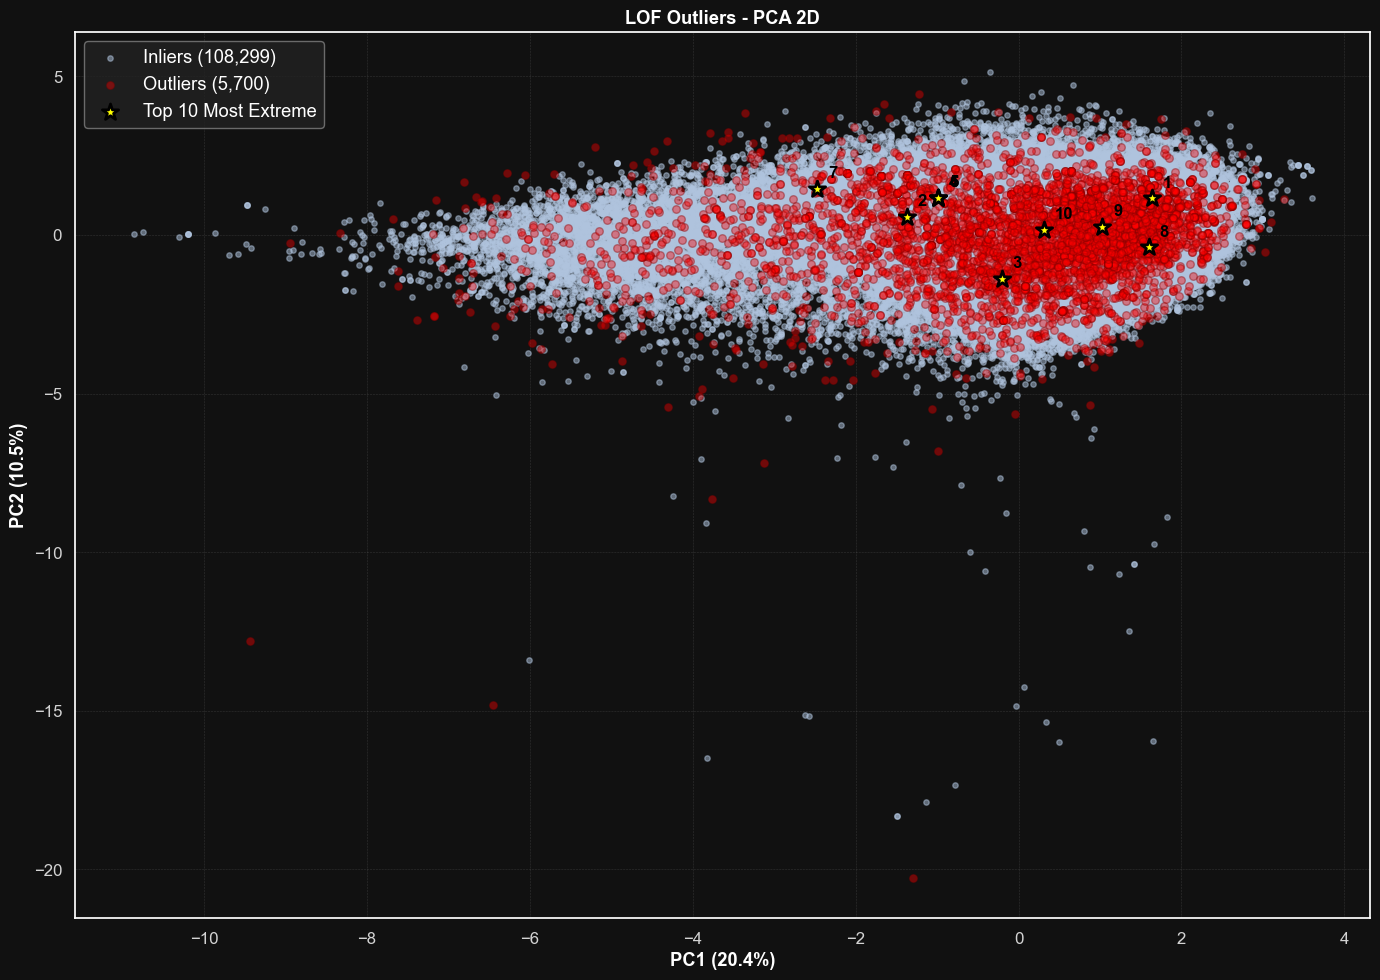

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np


# PCA solo sulle features (esclude ultime 2 colonne)
feature_cols = X_final.columns[:-2]
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_final[feature_cols])

# Plot
fig, ax = plt.subplots(figsize=(14, 10))

# Maschere semplici
inliers_mask = X_final["lof_labels"] == 1
outliers_mask = X_final["lof_labels"] == -1

# Plot
ax.scatter(X_pca[inliers_mask, 0], X_pca[inliers_mask, 1],
          c='lightsteelblue', alpha=0.5, s=15, label=f'Inliers ({np.sum(inliers_mask):,})')

ax.scatter(X_pca[outliers_mask, 0], X_pca[outliers_mask, 1],
          c='red', s=30, alpha=0.4, edgecolors='darkred', linewidth=1,
          label=f'Outliers ({np.sum(outliers_mask):,})')

# Top 10 - SEMPLICE
top_10_idx = X_final.nsmallest(10, "lof_scores").index

ax.scatter(X_pca[top_10_idx, 0], X_pca[top_10_idx, 1],
          c='yellow', s=150, marker='*', linewidth=2, edgecolors='black',
          label='Top 10 Most Extreme', zorder=5)

# Annotazioni
for i, idx in enumerate(top_10_idx):
    ax.annotate(f'{i+1}', (X_pca[idx, 0], X_pca[idx, 1]),
               xytext=(8, 8), textcoords='offset points',
               fontsize=12, fontweight='bold', color='black')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('LOF Outliers - PCA 2D')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{plots_dir}/lof_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


#### Elimino gli outliers rilevati

In [13]:
# Elimina outliers da df_final
df_clean = df_final[df_final["lof_labels"] == 1].copy()

# Rimuovi le colonne LOF dal dataset pulito
df_clean = df_clean.drop(columns=["lof_labels", "lof_scores"])

# Statistiche
n_original = len(df_final)
n_clean = len(df_clean)
n_removed = n_original - n_clean
removal_rate = (n_removed / n_original) * 100

print(f"📊 OUTLIER REMOVAL SUMMARY:")
print(f"Original dataset: {n_original:,} tracks")
print(f"Clean dataset: {n_clean:,} tracks")
print(f"Outliers removed: {n_removed:,} ({removal_rate:.2f}%)")


📊 OUTLIER REMOVAL SUMMARY:
Original dataset: 113,999 tracks
Clean dataset: 108,299 tracks
Outliers removed: 5,700 (5.00%)


#### Salvo il Dataset pulito

In [14]:
# Salva dataset pulito
clean_filename = "spotify_cleaned.csv"
df_clean.to_csv(os.path.join(dataset_dir, clean_filename), index=False)

print(f"\n✅ Dataset pulito salvato come '{clean_filename}'")
print(f"Shape finale: {df_clean.shape}")


✅ Dataset pulito salvato come 'spotify_cleaned.csv'
Shape finale: (108299, 66)
